In [3]:
# code here
import cv2
import matplotlib.pyplot as plt
import numpy as np

1)	Abrir as imagens coloridas e mostrar a imagem e seus histogramas (separados) cada canal de cor. Considerar os seguintes sistemas de cores:
a.	RGB
b.	HSV ou HSI
c.	Lab


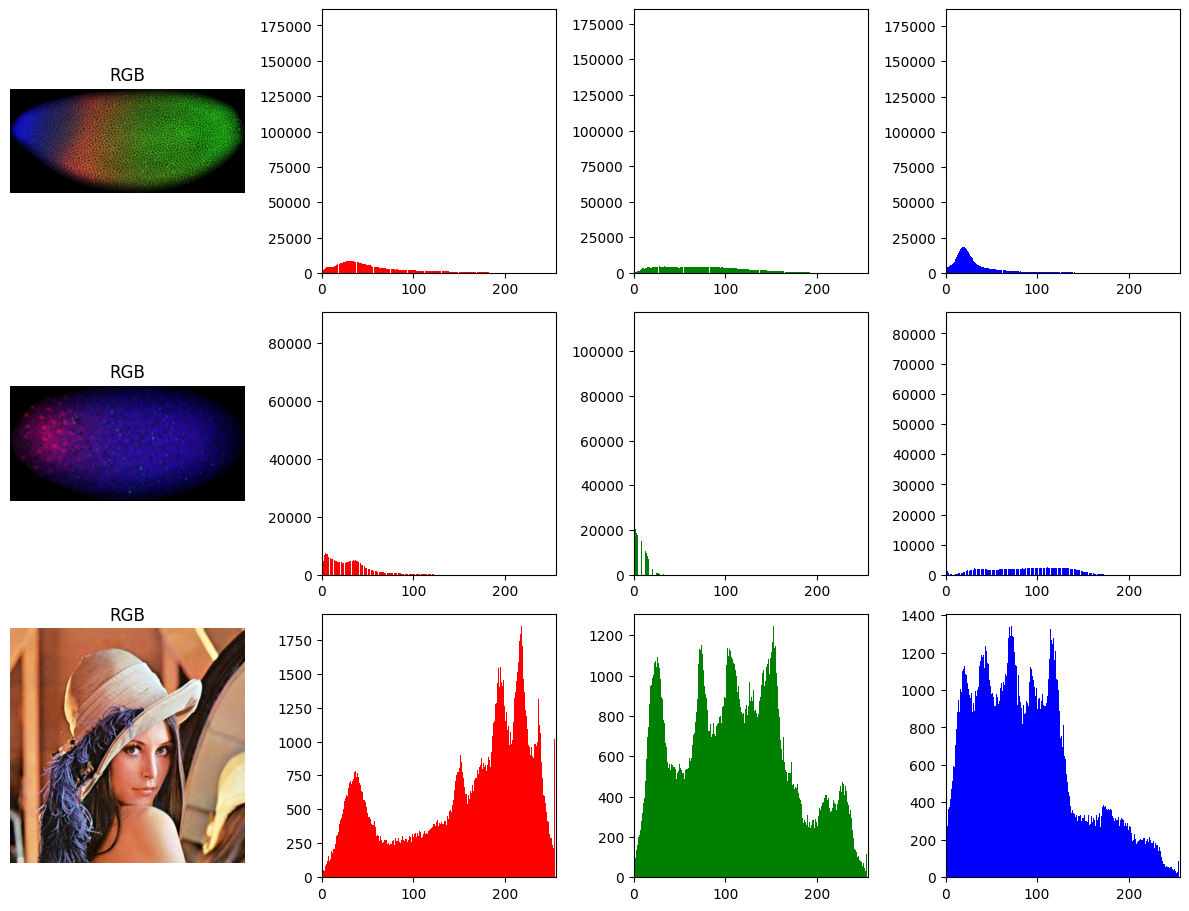

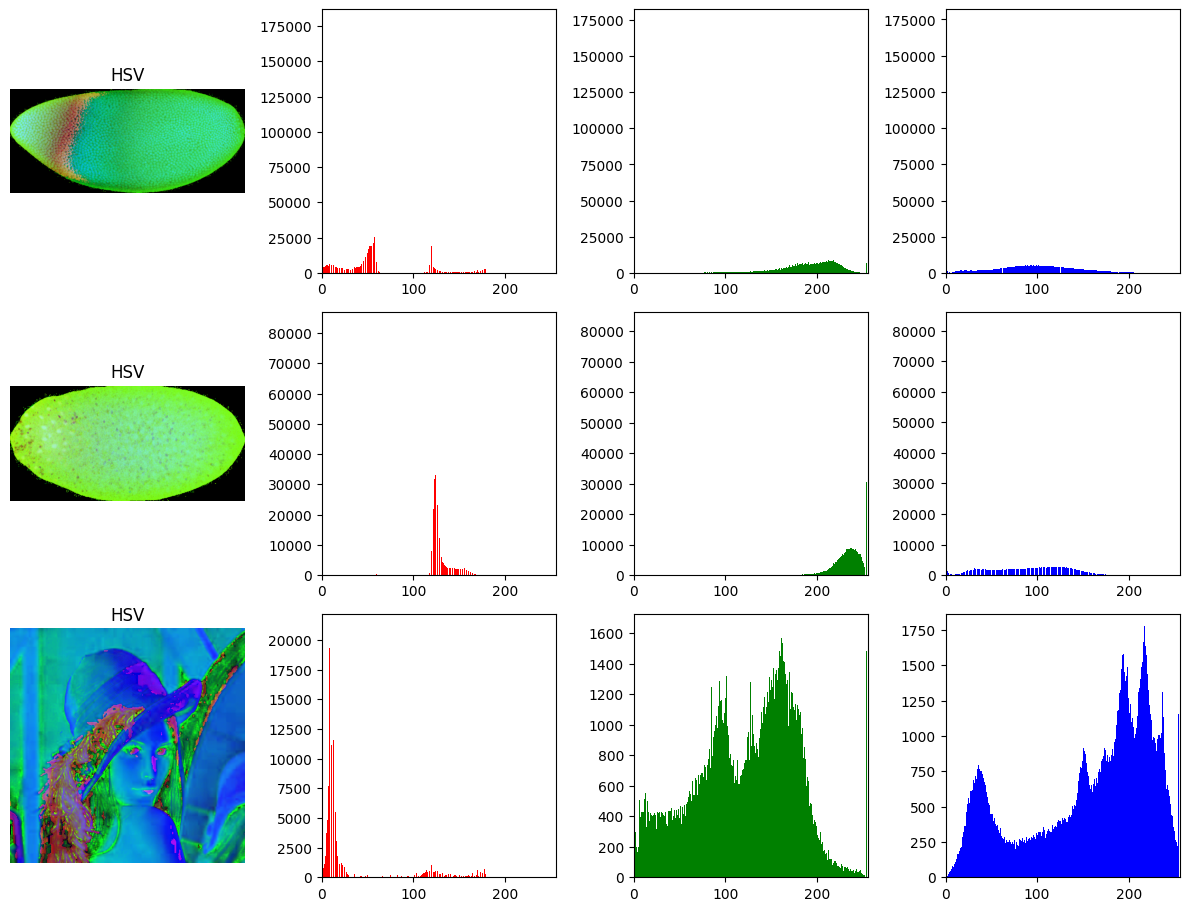

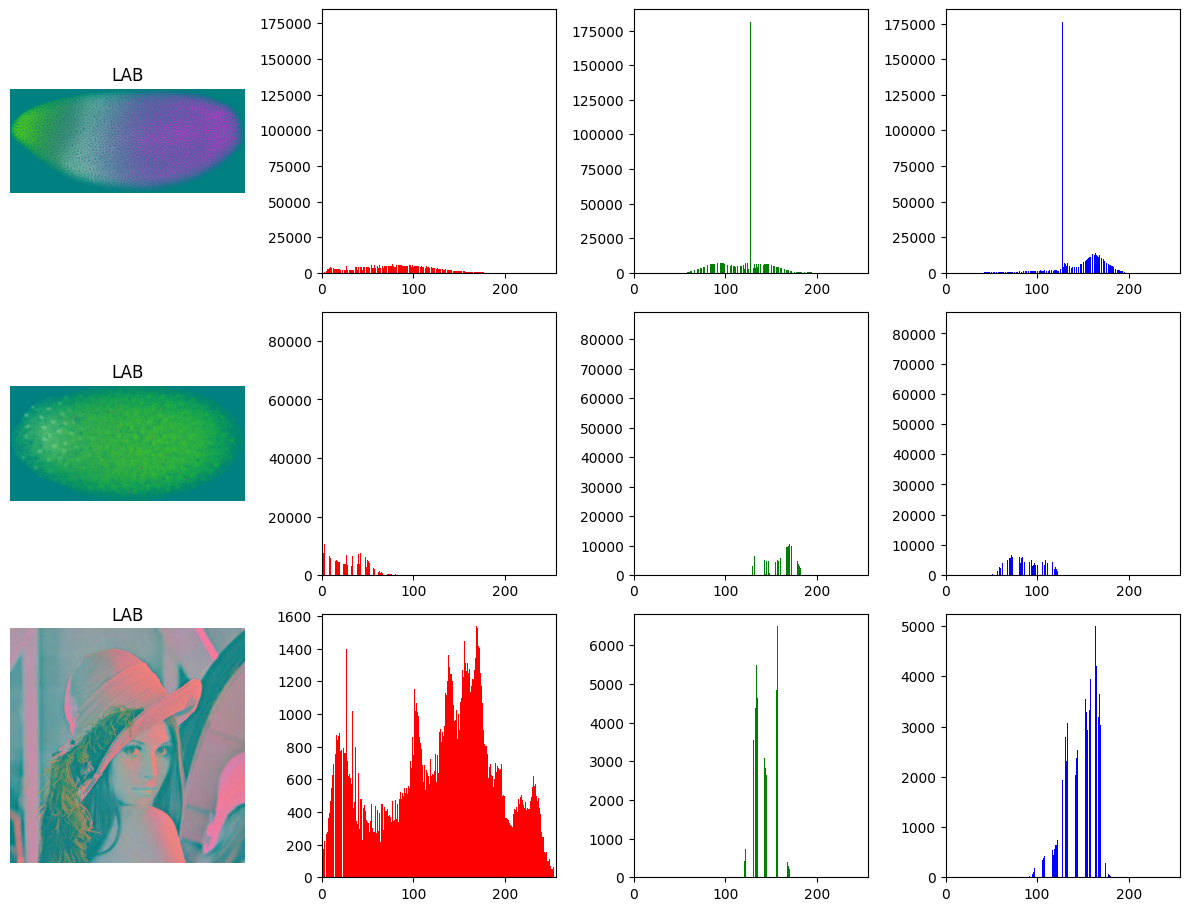

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def mostrar(img, titulo, pos):
    plt.subplot(4,4,pos)
    plt.imshow(img)
    plt.title(titulo)
    plt.axis("off")

def histograma(canal, cor, pos):
    plt.subplot(4,4,pos)
    plt.hist(canal.ravel(), bins=256, color=cor)
    plt.xlim([0,256])

# leitura
img1 = cv2.imread("image.jpg")
img2 = cv2.imread("image2.jpg")
img3 = cv2.imread("Lenna.jpg")

# BGR -> RGB
img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
img3 = cv2.cvtColor(img3, cv2.COLOR_BGR2RGB)

imgs = [img1, img2, img3]




plt.figure(figsize=(12,12))

linha = 0

for img in imgs:
    # mostrar imagem
    mostrar(img, "RGB", linha*4+1)

    # canais RGB
    r = img[:,:,0]
    g = img[:,:,1]
    b = img[:,:,2]

    histograma(r, 'red', linha*4+2)
    histograma(g, 'green', linha*4+3)
    histograma(b, 'blue', linha*4+4)

    linha += 1

plt.tight_layout()
plt.show()


# hsv

plt.figure(figsize=(12,12))
linha = 0

for img in imgs:
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

    mostrar(hsv, "HSV", linha*4+1)

    h = hsv[:,:,0]
    s = hsv[:,:,1]
    v = hsv[:,:,2]

    histograma(h, 'red', linha*4+2)
    histograma(s, 'green', linha*4+3)
    histograma(v, 'blue', linha*4+4)

    linha += 1

plt.tight_layout()
plt.show()


# lab

plt.figure(figsize=(12,12))
linha = 0

for img in imgs:
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)

    mostrar(lab, "LAB", linha*4+1)

    l = lab[:,:,0]
    a = lab[:,:,1]
    b = lab[:,:,2]

    histograma(l, 'red', linha*4+2)
    histograma(a, 'green', linha*4+3)
    histograma(b, 'blue', linha*4+4)

    linha += 1

plt.tight_layout()
plt.show()

2)	Utilizando a imagem do mandrill, faça rotinas para detecção do focinho (região vermelha e azul). Utilize algum algoritmo de limiarização.

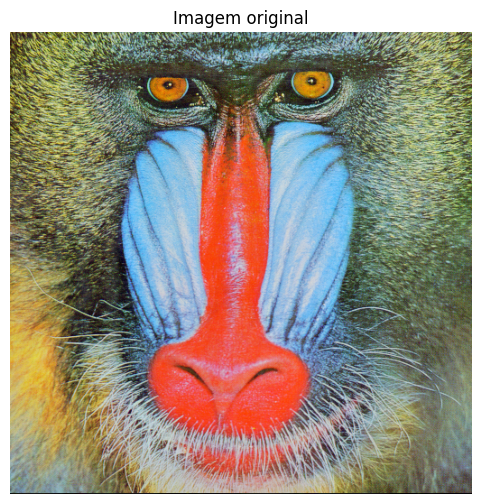

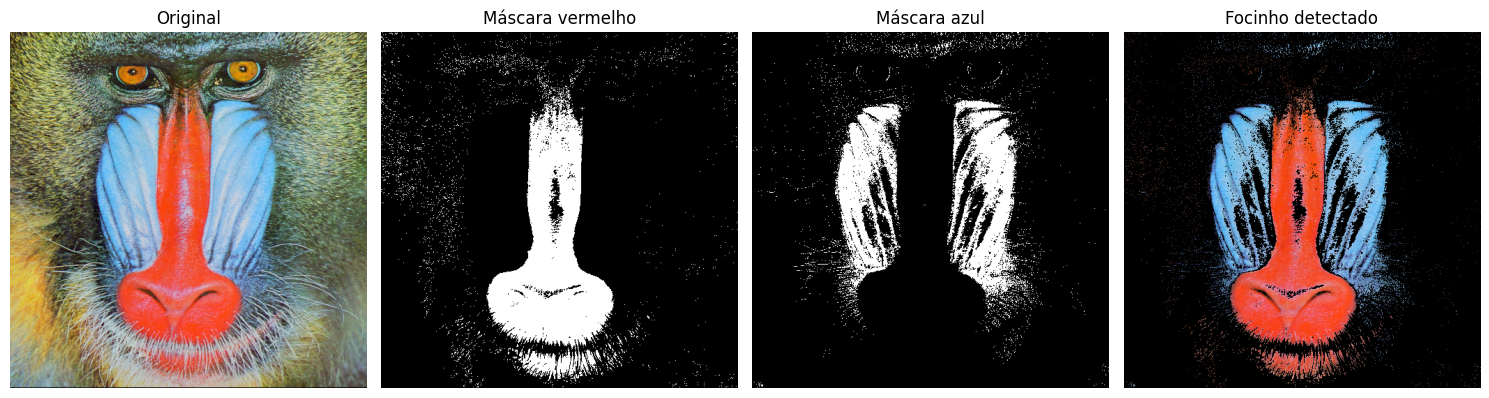

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_mand = cv2.imread("mandrill.tiff", cv2.IMREAD_COLOR)
img_mand_RGB = cv2.cvtColor(img_mand, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img_mand_RGB)
plt.title("Imagem original")
plt.axis("off")
plt.show()

# converter para HSV
img_hsv = cv2.cvtColor(img_mand, cv2.COLOR_BGR2HSV)

# vermelho no HSV costuma ficar em duas faixas
lower_red1 = np.array([0, 80, 50])
upper_red1 = np.array([10, 255, 255])

lower_red2 = np.array([170, 80, 50])
upper_red2 = np.array([180, 255, 255])

# azul
lower_blue = np.array([100, 80, 50])
upper_blue = np.array([140, 255, 255])

# limiarização por cor
mask_red1 = cv2.inRange(img_hsv, lower_red1, upper_red1)
mask_red2 = cv2.inRange(img_hsv, lower_red2, upper_red2)
mask_red = cv2.bitwise_or(mask_red1, mask_red2)

mask_blue = cv2.inRange(img_hsv, lower_blue, upper_blue)

# junta vermelho e azul
mask_focinho = cv2.bitwise_or(mask_red, mask_blue)

# aplicar máscara na imagem
resultado = cv2.bitwise_and(img_mand_RGB, img_mand_RGB, mask=mask_focinho)

plt.figure(figsize=(15,5))

plt.subplot(1,4,1)
plt.imshow(img_mand_RGB)
plt.title("Original")
plt.axis("off")

plt.subplot(1,4,2)
plt.imshow(mask_red, cmap="gray")
plt.title("Máscara vermelho")
plt.axis("off")

plt.subplot(1,4,3)
plt.imshow(mask_blue, cmap="gray")
plt.title("Máscara azul")
plt.axis("off")

plt.subplot(1,4,4)
plt.imshow(resultado)
plt.title("Focinho detectado")
plt.axis("off")

plt.tight_layout()
plt.show()

3)	Utilizando a imagem HE.jpg, tente detectar e contar a quantidade de núcleos celulares (em azul). Aplicar o Ostu para os 9 canais de cores e avaliar qual foi melhor (R,G,B,H,S,V,L,a,b)

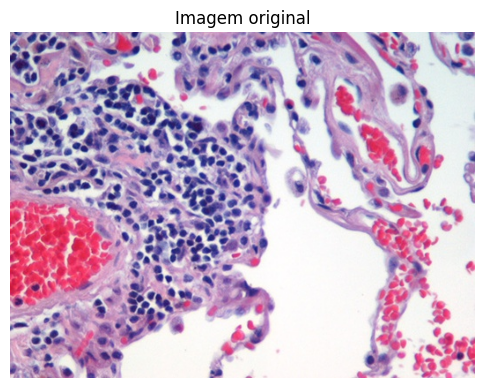

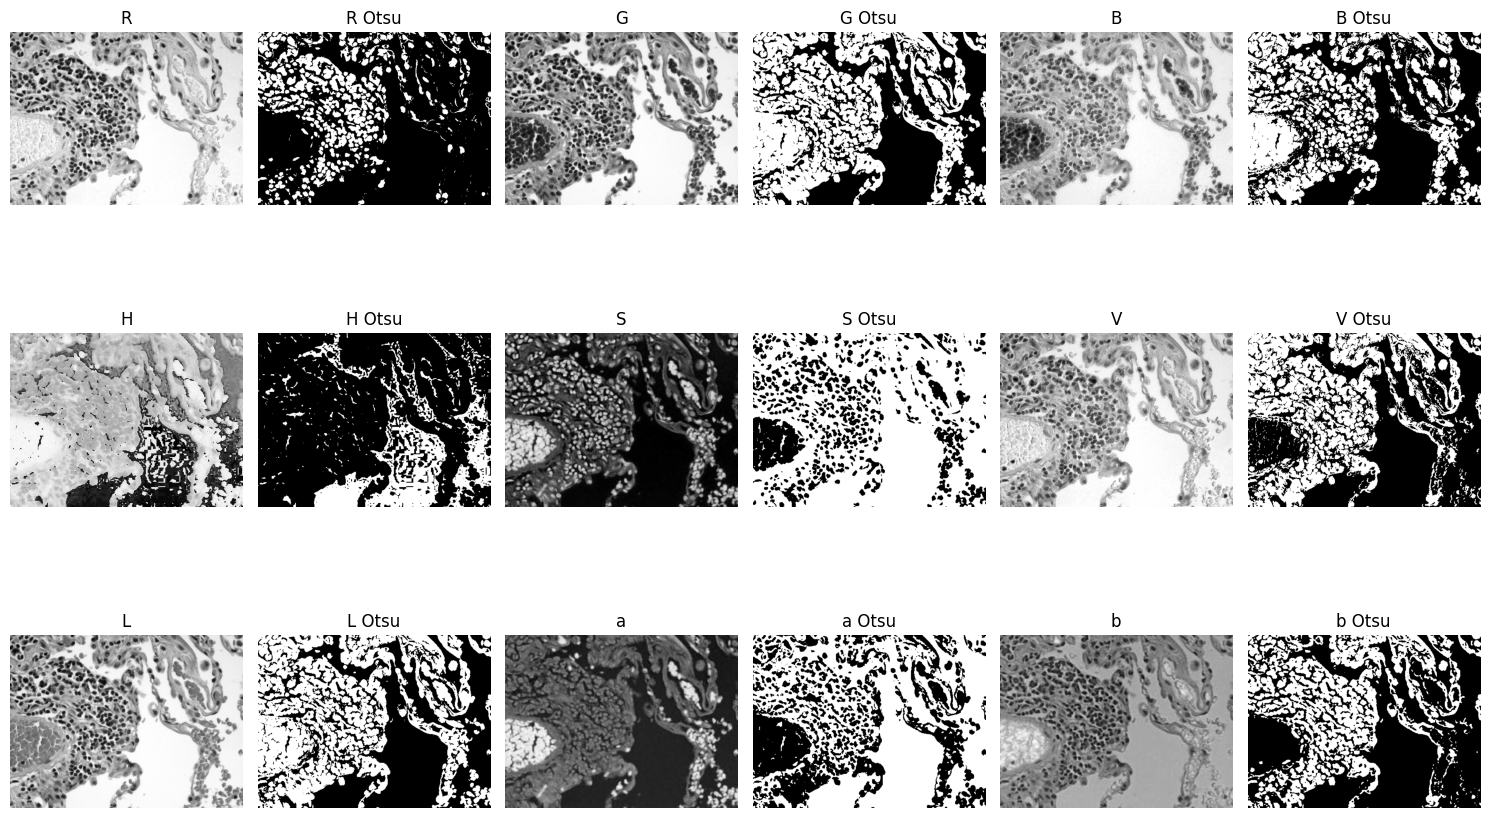

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img_he = cv2.imread("HE.jpg", cv2.IMREAD_COLOR)
img_he_RGB = cv2.cvtColor(img_he, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img_he_RGB)
plt.title("Imagem original")
plt.axis("off")
plt.show()

# separando canais RGB
R = img_he_RGB[:,:,0]
G = img_he_RGB[:,:,1]
B = img_he_RGB[:,:,2]

# HSV
img_hsv = cv2.cvtColor(img_he_RGB, cv2.COLOR_RGB2HSV)
H = img_hsv[:,:,0]
S = img_hsv[:,:,1]
V = img_hsv[:,:,2]

# Lab
img_lab = cv2.cvtColor(img_he_RGB, cv2.COLOR_RGB2LAB)
L = img_lab[:,:,0]
a = img_lab[:,:,1]
b = img_lab[:,:,2]

canais = [R,G,B,H,S,V,L,a,b]
nomes = ["R","G","B","H","S","V","L","a","b"]

plt.figure(figsize=(15,10))

melhor_mascara = None
melhor_nome = ""

for i in range(9):
    canal = canais[i]

    # Otsu
    t, binaria = cv2.threshold(canal, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # em alguns canais os núcleos ficam escuros, então inverter pode ajudar
    t2, binaria_inv = cv2.threshold(canal, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

    plt.subplot(3,6,2*i+1)
    plt.imshow(canal, cmap="gray")
    plt.title(nomes[i])
    plt.axis("off")

    plt.subplot(3,6,2*i+2)
    plt.imshow(binaria_inv, cmap="gray")
    plt.title(nomes[i] + " Otsu")
    plt.axis("off")

plt.tight_layout()
plt.show()